# 6. Scoring de la base y panel de resultados
**RetailNova — Caso 1 (SCY1102 Gestión de Proyectos de Datos, Sección 001D)** · Hurtubia · Pacheco · Curi · Gómez

Se aplica el modelo a los 12 meses completos y se asigna un nivel de riesgo por percentiles de probabilidad (**Alto** = 10 % superior, **Medio** = siguiente 24 %, **Bajo** = resto). El panel de resultados se construye **dentro del cuaderno** con tablas y gráficos de matplotlib. Código en `src/scoring.py` y `src/seguimiento.py`.

## 6.1 Configuración y scoring

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # permite importar src/ desde notebooks/

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config as cfg

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.3f}".format

In [2]:
from src.modelado import cargar_modelo, cargar_seleccion
from src.scoring import puntuar
from src.seguimiento import cargar_seguimiento

df = pd.read_csv(cfg.CSV_PREPARADO)
pipe, sel = cargar_modelo(), cargar_seleccion()
scored = puntuar(df, pipe)

riesgo_abandono
Alto      5135
Medio    12323
Bajo     33888
Exportado /home/claude/retailnova_nb/data/processed/retailnova_clientes_12m_scored.csv


## 6.2 Indicadores clave (KPIs)

In [3]:
alto = scored[scored["riesgo_abandono"] == "Alto"]
kpis = pd.DataFrame({
    "Indicador": ["Clientes (12 meses)", "Tasa de abandono real", "Clientes en riesgo Alto", "% de la base en riesgo Alto", "Monto acumulado en riesgo Alto"],
    "Valor": [f"{len(scored):,}".replace(",", "."), f"{scored['abandono'].mean():.1%}", f"{len(alto):,}".replace(",", "."),
              f"{len(alto)/len(scored):.1%}", f"${alto['monto_total_acumulado'].sum()/1e6:,.1f} M"],
})
kpis.set_index("Indicador")

,Valor
Indicador,
Clientes (12 meses),51.346
Tasa de abandono real,24.0%
Clientes en riesgo Alto,5.135
% de la base en riesgo Alto,10.0%
Monto acumulado en riesgo Alto,$606.1 M


## 6.3 Riesgo por nivel y por región
¿Cuántos clientes hay en cada nivel y se concentra el riesgo en alguna región? (equidad, RNF6)

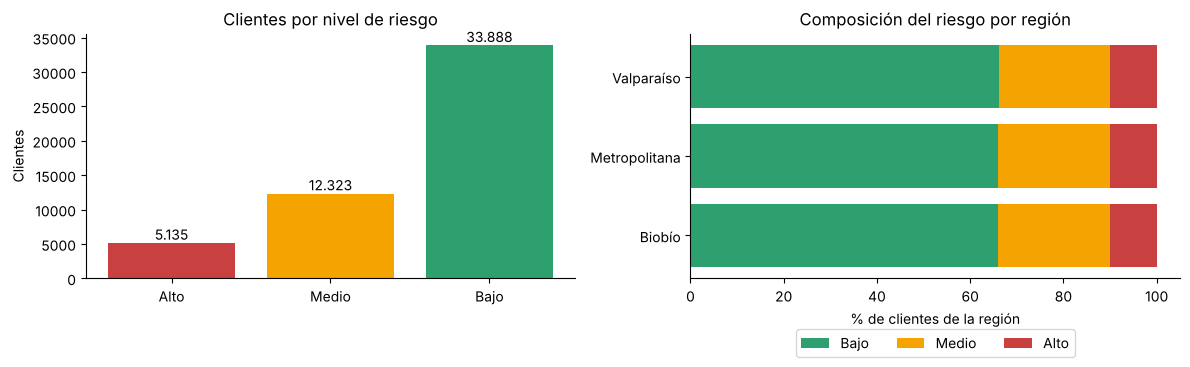

In [4]:
COL = {"Bajo": "#2E9F6E", "Medio": "#F4A300", "Alto": "#C94040"}
niv = scored["riesgo_abandono"].value_counts().reindex(cfg.NIVELES_RIESGO)
por_region = pd.crosstab(scored["region"], scored["riesgo_abandono"], normalize="index")[["Bajo", "Medio", "Alto"]]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].bar(niv.index, niv.values, color=[COL[k] for k in niv.index])
for i, v in enumerate(niv.values): axs[0].text(i, v, f"{v:,}".replace(",", "."), ha="center", va="bottom")
axs[0].set_title("Clientes por nivel de riesgo"); axs[0].set_ylabel("Clientes")
izq = np.zeros(len(por_region))
for k in ["Bajo", "Medio", "Alto"]:
    axs[1].barh(por_region.index, por_region[k]*100, left=izq, color=COL[k], label=k); izq += por_region[k].values*100
axs[1].set_xlabel("% de clientes de la región"); axs[1].set_title("Composición del riesgo por región"); axs[1].legend(ncol=3, loc="lower center", bbox_to_anchor=(.5, -.35))
plt.tight_layout(); plt.show()

## 6.4 Distribución de la probabilidad
¿El modelo separa bien a los clientes? Los colores marcan el nivel de riesgo y la línea punteada el umbral de decisión.

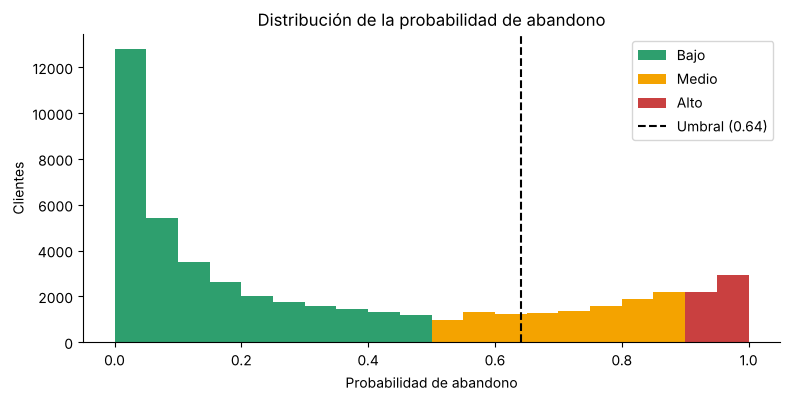

In [5]:
bins = np.linspace(0, 1, 21)
fig, ax = plt.subplots(figsize=(9, 4))
for k in ["Bajo", "Medio", "Alto"]:
    ax.hist(scored.loc[scored["riesgo_abandono"] == k, "prob_abandono"], bins=bins, color=COL[k], label=k)
ax.axvline(sel["umbral_decision"], color="black", ls="--", label=f"Umbral ({sel['umbral_decision']:.2f})")
ax.set_xlabel("Probabilidad de abandono"); ax.set_ylabel("Clientes"); ax.set_title("Distribución de la probabilidad de abandono"); ax.legend()
plt.show()

## 6.5 Recencia vs. frecuencia (muestra de 2.500 clientes)
¿Qué comportamiento hay detrás del riesgo? La recencia **no entra al modelo** (fuga de datos); aquí solo se usa para describir.

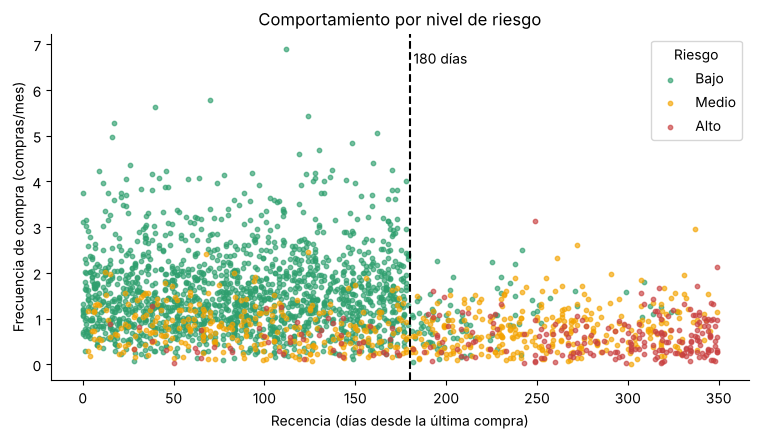

In [6]:
m = scored.sample(2500, random_state=cfg.SEMILLA)
fig, ax = plt.subplots(figsize=(9, 4.5))
for k in ["Bajo", "Medio", "Alto"]:
    s = m[m["riesgo_abandono"] == k]
    ax.scatter(s["recencia_dias"], s["frecuencia_compra"], s=10, alpha=.65, color=COL[k], label=k)
ax.axvline(180, color="black", ls="--"); ax.text(182, ax.get_ylim()[1]*.95, "180 días", va="top")
ax.set_xlabel("Recencia (días desde la última compra)"); ax.set_ylabel("Frecuencia de compra (compras/mes)"); ax.legend(title="Riesgo")
ax.set_title("Comportamiento por nivel de riesgo")
plt.show()

## 6.6 Top 20 clientes a contactar primero

In [7]:
top = (scored.sort_values("prob_abandono", ascending=False).head(20)
       [["id_cliente", "region", "canal_compra", "prob_abandono", "recencia_dias", "monto_total_acumulado", "riesgo_abandono"]]
       .reset_index(drop=True))
top.index += 1
top.style.format({"prob_abandono": "{:.1%}", "monto_total_acumulado": "${:,.0f}"})

,id_cliente,region,canal_compra,prob_abandono,recencia_dias,monto_total_acumulado,riesgo_abandono
1,CL129723,Metropolitana,Mixto,99.9%,344,"$113,400",Alto
2,CL182255,Metropolitana,Tienda física,99.9%,338,"$19,800",Alto
3,CL071395,Metropolitana,Tienda física,99.9%,340,"$93,200",Alto
4,CL006806,Valparaíso,Tienda física,99.9%,337,"$116,400",Alto
5,CL006555,Metropolitana,Mixto,99.9%,349,"$15,000",Alto
6,CL050760,Metropolitana,Tienda física,99.9%,317,"$138,400",Alto
7,CL139872,Metropolitana,E-commerce,99.9%,214,"$57,600",Alto
8,CL156786,Metropolitana,Tienda física,99.9%,249,"$82,200",Alto
9,CL075732,Valparaíso,Tienda física,99.9%,346,"$424,000",Alto
10,CL076065,Valparaíso,E-commerce,99.9%,313,"$48,000",Alto


## 6.7 Resultados del modelo

In [8]:
import json
ev = json.loads((cfg.RESULTADOS / "evaluacion" / "evaluacion_final.json").read_text(encoding="utf-8"))
print("Modelo elegido:", ev["modelo"], "· AUC CV:", {k: round(v[0], 3) for k, v in sel["auc_cv"].items()})
pd.DataFrame(ev["metricas"])

Modelo elegido: Regresión Logística · AUC CV: {'Random Forest': 0.909, 'Regresión Logística': 0.908}


,Umbral,ROC_AUC,PR_AUC,Recall,Precisión,F1,Alertas generadas
0,0.50 (referencia),0.907,0.745,0.852,0.589,0.697,3565
1,0.6415 (OOF),0.907,0.745,0.740,0.646,0.690,2820


In [9]:
pd.DataFrame(ev["regional"])

,Región,N clientes (test),Tasa abandono real,F1,Recall,Diferencia vs. F1 general (%),¿Cumple RNF6 (<10%)?
0,Biobío,1180,0.226,0.708,0.775,2.600,Sí
1,Metropolitana,7387,0.237,0.689,0.743,0.100,Sí
2,Valparaíso,1703,0.262,0.680,0.704,1.400,Sí


## 6.8 Gestión del proyecto: tareas planificadas vs. ejecutadas
Datos de `seguimiento/tareas.json` (corte indicado en el archivo). El resumen se calcula, no se escribe a mano.

In [10]:
seg = cargar_seguimiento()
r = seg["resumen"]
print(f"{r['completadas']}/{r['total']} tareas completadas ({r['avance_pct']} %) · {r['en_proceso']} en proceso · {r['desviaciones']} desviaciones")
pd.DataFrame(seg["tareas"]).set_index("id")

10/11 tareas completadas (90.9 %) · 1 en proceso · 3 desviaciones


,titulo,responsable,planificado,ejecutado,estado,evidencia
id,,,,,,
T01,Aprobación del alcance,Hurtubia,01–15 ago,01–18 ago,Completado,Plan de proyecto EP3
T02,Generación de datos sintéticos (3 años),Gómez,01–15 sep,01–15 sep,Completado,src/generador_dataset.py
T03,"Limpieza, imputación y validación",Curi,16–30 sep,16–30 sep,Completado,src/pipeline_datos.py
T04,Feature engineering (RFM),Pacheco,01–07 oct,01–09 oct,Completado,src/pipeline_datos.py · agregar_rfm
T05,Modelamiento y selección de modelo,"Gómez, Curi",08–20 oct,08–25 oct,Completado,src/modelado.py
T06,Evaluación regional (RNF6),Hurtubia,21–25 oct,26–28 oct,Completado,src/equidad_regional.py
T07,Explicabilidad (SHAP),Pacheco,26–31 oct,29–31 oct,Completado,src/explicabilidad.py
T08,Panel de resultados,Curi,01–05 nov,01–03 nov,Completado,notebooks/06_scoring_y_panel.ipynb
T09,Tablero de gestión y reportes de estado,Gómez,15–31 oct,03 nov,Completado,seguimiento/tareas.json


In [11]:
for d in seg["desviaciones"]:
    print(f"{d['id']} · {d['tipo']}\n  {d['descripcion']}\n  Acción: {d['accion']}\n")

DV-1 · Técnica
  En una iteración intermedia Biobío no cumplía RNF6 (brecha de F1 de 12,3 %; muestra de prueba más chica).
  Acción: Se reforzó la validación (CV + umbral OOF) y se volvió a auditar; versión final con brecha máxima de 2,6 %. Riesgo a vigilar con datos reales.

DV-2 · Gestión
  El tablero de gestión se actualizó al cierre del ciclo y no en paralelo, como estaba planificado.
  Acción: Sin impacto en la fecha de entrega. Para EP6 se actualiza semanalmente.

DV-3 · Alcance
  Se agregó validación cruzada de 5 folds y ajuste de umbral por OOF, no contemplados en el plan original (atrasó el modelamiento 5 días).
  Acción: Mejora deliberada de rigor metodológico; se registra el cambio para mantener la trazabilidad plan ↔ ejecución.



## 6.9 Limitaciones
- Datos 100 % sintéticos: el AUC alto refleja las reglas del generador, no el comportamiento real de RetailNova.
- Las probabilidades no están calibradas; el nivel de riesgo es relativo (percentiles) y sirve para priorizar, no para predecir cuántos clientes se irán.
- Con datos reales hay que volver a auditar la equidad regional (RNF6).